# GAN sur MNIST (DCGAN)

Ce notebook entraîne un **Generative Adversarial Network** qui génère des chiffres manuscrits MNIST
de bonne qualité en quelques minutes sur un Mac M1 (GPU `mps`), ou un peu plus lentement sur CPU.

On reprend les notations du cours :

* le **générateur** $G : \mathbf{z} \in \mathbb{R}^{l} \mapsto G(\mathbf{z}) \in \mathbb{R}^{d}$, avec $\mathbf{z} \sim p_z = \mathcal{N}(\mathbf{0}, \mathbf{I})$ ;
* le **discriminateur** $D : \mathbf{x} \in \mathbb{R}^{d} \mapsto D(\mathbf{x}) = \Pr(y = 1 \mid \mathbf{x}) \in [0,1]$ ;
* la fonction de loss
$$V(D,G) = \mathbb{E}_{\mathbf{x} \sim p_{\mathrm{data}}}\big[\log D(\mathbf{x})\big] + \mathbb{E}_{\mathbf{z} \sim p_z}\big[\log\big(1 - D(G(\mathbf{z}))\big)\big],$$
que $D$ maximise et que $G$ minimise (en pratique, $G$ minimise la version **non-saturante** $-\log D(G(\mathbf{z}))$).

**Pourquoi ce GAN marche mieux que celui du slide « Exemple » ?** Les ingrédients sont ceux de
l'article **DCGAN** (Radford, Metz & Chintala, 2015), devenus la recette standard :

1. **Architecture entièrement convolutive** : $G$ utilise des convolutions transposées (*upsampling*),
   $D$ des convolutions à pas 2 (*downsampling*), sans max-pooling.
2. **Batch Normalization** dans $G$ et dans $D$ (sauf sur la couche d'entrée de $D$ et la couche de sortie de $G$).
3. Activations **ReLU** dans $G$ (et $\tanh$ en sortie), **LeakyReLU(0.2)** dans $D$.
4. **Adam avec `lr = 2e-4` et $\beta_1 = 0.5$** (au lieu de $0.9$ par défaut : moins d'inertie, ce qui stabilise le jeu à deux joueurs).
5. Poids initialisés selon $\mathcal{N}(0, 0.02)$.

On ajoute deux astuces simples du cours (slide « Solutions pour stabiliser les GANs ») :
la **loss non-saturante** pour $G$ et le **label smoothing unilatéral** (labels « vrais » $= 0.9$ au lieu de $1$).

## 1. Librairies et device

In [1]:
import os, time, math
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision.utils import make_grid

# GPU Apple (Metal Performance Shaders) si disponible, sinon CUDA, sinon CPU
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("device :", device)

torch.manual_seed(0)       # reproductibilité (approximative sur GPU)
np.random.seed(0)

OUTPUT_DIR = "output_gan_mnist"     # images et poids produits par le notebook
FIG_DIR = "figures"                 # figures pour les slides (dossier du cours)
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

device : mps


## 2. Dataset MNIST

On normalise les pixels dans $[-1, 1]$, car la sortie de $G$ est un $\tanh$ (même intervalle).

MNIST est petit (60 000 images $28 \times 28$, ~47 Mo en `float32`) : on le **charge en entier sur le GPU**
et on tire nous-mêmes les mini-batchs. C'est équivalent à un `DataLoader(shuffle=True)`,
mais beaucoup plus rapide sur Mac (pas de conversion image par image, pas de copie CPU → GPU à chaque batch).

In [2]:
# On réutilise la copie locale de MNIST des TP si elle existe, sinon on la télécharge dans ./data
DATA_ROOT = "../TP/data" if os.path.isdir("../TP/data/MNIST") else "./data"
mnist = datasets.MNIST(DATA_ROOT, train=True, download=not os.path.isdir(os.path.join(DATA_ROOT, "MNIST")))

X = mnist.data.float().div(255.0)          # (60000, 28, 28), pixels dans [0, 1]
X = (X * 2.0 - 1.0).unsqueeze(1)           # (60000, 1, 28, 28), pixels dans [-1, 1]
X = X.to(device)
N = X.shape[0]
print("dataset :", tuple(X.shape), "| min =", X.min().item(), "| max =", X.max().item())

def batches(batch_size):
    # Mini-batchs aléatoires couvrant le dataset une fois (= une époque)
    perm = torch.randperm(N, device=device)
    for k in range(N // batch_size):        # on ignore le dernier batch incomplet
        yield X[perm[k * batch_size:(k + 1) * batch_size]]

dataset : (60000, 1, 28, 28) | min = -1.0 | max = 1.0


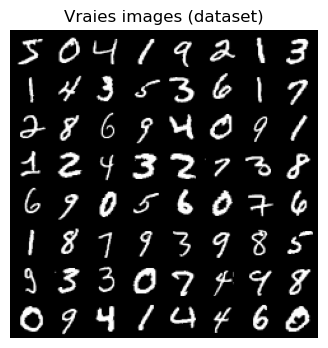

In [3]:
def show_grid(imgs, nrow=8, title=None, ax=None):
    # Affiche un tenseur (B, 1, 28, 28) à valeurs dans [-1, 1] sous forme de grille
    grid = make_grid(imgs.detach().cpu(), nrow=nrow, padding=2, normalize=True, value_range=(-1, 1))
    ax = ax or plt.gca()
    ax.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
    ax.axis("off")
    if title: ax.set_title(title)

plt.figure(figsize=(4, 4))
show_grid(X[:64], title="Vraies images (dataset)")
plt.show()

## 3. Les deux réseaux

### Générateur $G$

$\mathbf{z} \in \mathbb{R}^{100}$ est vu comme une « image » $100 \times 1 \times 1$, puis agrandie par des
convolutions transposées :

$$
\underbrace{100 \times 1 \times 1}_{\mathbf{z}}
\;\xrightarrow{\text{ConvT}}\; 128 \times 7 \times 7
\;\xrightarrow{\text{ConvT}}\; 64 \times 14 \times 14
\;\xrightarrow{\text{ConvT}}\; \underbrace{1 \times 28 \times 28}_{G(\mathbf{z})}
$$

### Discriminateur $D$

Chemin inverse, avec des convolutions à pas 2 :
$1 \times 28 \times 28 \to 32 \times 14 \times 14 \to 64 \times 7 \times 7 \to 1$.

Les réseaux sont volontairement **petits** (MNIST est simple) : une époque prend ~15 s sur un M1 Pro.
Essais faits pour ce notebook : doubler `ngf`/`ndf` coûte ~3× plus cher sans gain visible à temps égal ;
ce qui aide vraiment, c'est le **nombre de mises à jour** (batch de 64 plutôt que 128, et plus d'époques).

**Remarque importante.** $D$ renvoie un **logit** $a(\mathbf{x}) \in \mathbb{R}$ et non directement une probabilité :
$D(\mathbf{x}) = \sigma\big(a(\mathbf{x})\big)$. On utilise alors `BCEWithLogitsLoss`, qui calcule
$\log \sigma(a)$ et $\log(1 - \sigma(a))$ de façon numériquement stable (pas de $\log 0$ quand $D$ sature).
C'est mathématiquement la même loss que `Sigmoid` + `BCELoss`.

In [4]:
LATENT_DIM = 100   # dimension l de l'espace latent

class Generator(nn.Module):
    def __init__(self, zdim=LATENT_DIM, ngf=32):
        super().__init__()
        self.net = nn.Sequential(
            # z : (B, 100, 1, 1) -> (B, 128, 7, 7)
            nn.ConvTranspose2d(zdim, 4 * ngf, kernel_size=7, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(4 * ngf), nn.ReLU(True),
            # -> (B, 64, 14, 14)
            nn.ConvTranspose2d(4 * ngf, 2 * ngf, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(2 * ngf), nn.ReLU(True),
            # -> (B, 1, 28, 28), pixels dans [-1, 1]  (pas de BatchNorm sur la couche de sortie)
            nn.ConvTranspose2d(2 * ngf, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z.view(z.size(0), -1, 1, 1))


class Discriminator(nn.Module):
    def __init__(self, ndf=32):
        super().__init__()
        self.net = nn.Sequential(
            # x : (B, 1, 28, 28) -> (B, 32, 14, 14)   (pas de BatchNorm sur la 1re couche)
            nn.Conv2d(1, ndf, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            # -> (B, 64, 7, 7)
            nn.Conv2d(ndf, 2 * ndf, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(2 * ndf), nn.LeakyReLU(0.2, inplace=True),
            # -> (B, 1, 1, 1) : un logit par image
            nn.Conv2d(2 * ndf, 1, kernel_size=7, stride=1, padding=0),
        )

    def forward(self, x):
        return self.net(x).view(-1)        # logits a(x), et D(x) = sigmoid(a(x))


def init_weights(m):
    # Initialisation DCGAN : poids ~ N(0, 0.02), BatchNorm : gamma ~ N(1, 0.02), beta = 0
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

G = Generator().to(device); G.apply(init_weights)
D = Discriminator().to(device); D.apply(init_weights)

n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"G : {n_params(G):,} paramètres | D : {n_params(D):,} paramètres")

# Vérification des dimensions
z = torch.randn(16, LATENT_DIM, device=device)
print("G(z) :", tuple(G(z).shape), "| D(G(z)) :", tuple(D(G(z)).shape))

G : 759,681 paramètres | D : 36,577 paramètres
G(z) : (16, 1, 28, 28) | D(G(z)) : (16,)


## 4. Losses et optimiseurs

Pour un batch $\{\mathbf{x}_i\}_{i=1}^m$ de vraies images et $\{\mathbf{z}_j\}_{j=1}^m \sim p_z$ :

* **Discriminateur** (il maximise $\widehat V$, donc minimise) :
$$L_D = -\frac{1}{m}\sum_{i=1}^m \log D(\mathbf{x}_i) \;-\; \frac{1}{m}\sum_{j=1}^m \log\big(1 - D(G(\mathbf{z}_j))\big)$$
C'est exactement une **BCE** avec la cible $y=1$ pour les vraies images et $y=0$ pour les fausses.

* **Générateur**, forme **non-saturante** :
$$L_G^{\mathrm{NS}} = -\frac{1}{m}\sum_{j=1}^m \log D\big(G(\mathbf{z}_j)\big)$$
C'est une **BCE** sur les fausses images avec la cible $y = 1$ : $G$ veut que $D$ les classe « vraies ».

*Pourquoi non-saturante ?* Au début, $D$ repère facilement les fausses images : $D(G(\mathbf{z})) = \sigma(a) \approx 0$.
Or $\frac{\partial}{\partial a}\log(1-\sigma(a)) = -\sigma(a) \approx 0$ (plus de gradient pour $G$), alors que
$\frac{\partial}{\partial a}\big(-\log\sigma(a)\big) = -(1-\sigma(a)) \approx -1$ (gradient fort).

**Label smoothing unilatéral** : pour $D$, on remplace la cible $1$ des vraies images par $0.9$
(jamais celle des fausses). Cela empêche $D$ de devenir trop sûr de lui et garde des gradients utiles pour $G$.

In [5]:
LR, BETAS = 2e-4, (0.5, 0.999)     # réglages DCGAN
REAL_LABEL = 0.9                   # label smoothing unilatéral (1.0 pour le désactiver)

opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=BETAS)
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=BETAS)

bce = nn.BCEWithLogitsLoss()       # = Sigmoid + BCELoss, en plus stable

## 5. Boucle d'entraînement (alternée)

À chaque itération :

1. **Mise à jour de $D$** : une descente de gradient sur $L_D$ (vraies images avec cible $0.9$, fausses avec cible $0$).
   Les fausses images sont **détachées** (`fake.detach()`) : ce pas ne doit pas modifier $G$.
2. **Mise à jour de $G$** : une descente de gradient sur $L_G^{\mathrm{NS}}$ ; le gradient traverse $D$ (dont les poids ne bougent pas, seul `opt_G` fait un pas).

On suit aussi $D(\mathbf{x})$ et $D(G(\mathbf{z}))$ en moyenne : à l'équilibre idéal du cours, les deux valent $\tfrac12$.

Un vecteur de bruit **fixe** `fixed_z` permet de voir comment les *mêmes* points latents évoluent au cours de l'entraînement.

In [6]:
EPOCHS = int(os.environ.get("GAN_EPOCHS", 30))   # ~30 époques ≈ 8 min sur M1 Pro
BATCH_SIZE = 64                                   # petit batch = plus de mises à jour par époque
SNAPSHOT_EPOCHS = sorted({1, 3, 10, 20, EPOCHS} & set(range(1, EPOCHS + 1)))

fixed_z = torch.randn(64, LATENT_DIM, device=device)
history = {"loss_D": [], "loss_G": [], "D_real": [], "D_fake": []}
snapshots = {}

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    for real in batches(BATCH_SIZE):
        b = real.size(0)
        ones  = torch.full((b,), 1.0, device=device)
        smooth = torch.full((b,), REAL_LABEL, device=device)
        zeros = torch.zeros(b, device=device)

        # ---- 1. Discriminateur : minimiser L_D ----
        z = torch.randn(b, LATENT_DIM, device=device)
        fake = G(z)                                   # G(z_j)
        logits_real = D(real)                         # a(x_i)
        logits_fake = D(fake.detach())                # a(G(z_j)), sans gradient vers G
        loss_D = bce(logits_real, smooth) + bce(logits_fake, zeros)
        opt_D.zero_grad(set_to_none=True)
        loss_D.backward()
        opt_D.step()

        # ---- 2. Générateur : minimiser L_G^NS (cible y = 1 pour les fausses) ----
        logits_fake = D(fake)                         # D vient d'être mis à jour
        loss_G = bce(logits_fake, ones)
        opt_G.zero_grad(set_to_none=True)
        loss_G.backward()
        opt_G.step()

        # ---- suivi ----
        history["loss_D"].append(loss_D.item())
        history["loss_G"].append(loss_G.item())
        history["D_real"].append(torch.sigmoid(logits_real).mean().item())
        history["D_fake"].append(torch.sigmoid(logits_fake).mean().item())

    it = N // BATCH_SIZE
    print(f"époque {epoch:2d}/{EPOCHS} | L_D = {np.mean(history['loss_D'][-it:]):.3f} "
          f"| L_G = {np.mean(history['loss_G'][-it:]):.3f} "
          f"| D(x) = {np.mean(history['D_real'][-it:]):.2f} | D(G(z)) = {np.mean(history['D_fake'][-it:]):.2f} "
          f"| {time.time() - t0:5.0f} s")

    if epoch in SNAPSHOT_EPOCHS:
        G.eval()
        with torch.no_grad():
            snapshots[epoch] = G(fixed_z).cpu()
        G.train()

print(f"Entraînement terminé en {(time.time() - t0) / 60:.1f} min")
torch.save(G.state_dict(), os.path.join(OUTPUT_DIR, "G.pth"))
torch.save(D.state_dict(), os.path.join(OUTPUT_DIR, "D.pth"))

époque  1/30 | L_D = 0.806 | L_G = 1.732 | D(x) = 0.67 | D(G(z)) = 0.22 |    16 s


époque  2/30 | L_D = 0.818 | L_G = 1.682 | D(x) = 0.67 | D(G(z)) = 0.22 |    30 s


époque  3/30 | L_D = 0.887 | L_G = 1.595 | D(x) = 0.65 | D(G(z)) = 0.24 |    45 s


époque  4/30 | L_D = 0.936 | L_G = 1.545 | D(x) = 0.63 | D(G(z)) = 0.25 |    59 s


époque  5/30 | L_D = 0.934 | L_G = 1.563 | D(x) = 0.63 | D(G(z)) = 0.25 |    73 s


époque  6/30 | L_D = 0.925 | L_G = 1.596 | D(x) = 0.64 | D(G(z)) = 0.24 |    87 s


... (20 outputs left out)

époque 27/30 | L_D = 0.832 | L_G = 1.980 | D(x) = 0.68 | D(G(z)) = 0.20 |   402 s


époque 28/30 | L_D = 0.860 | L_G = 1.952 | D(x) = 0.68 | D(G(z)) = 0.20 |   416 s


époque 29/30 | L_D = 0.846 | L_G = 1.955 | D(x) = 0.68 | D(G(z)) = 0.20 |   430 s


époque 30/30 | L_D = 0.845 | L_G = 1.972 | D(x) = 0.68 | D(G(z)) = 0.20 |   445 s
Entraînement terminé en 7.4 min


## 6. Courbes d'entraînement

Attention : contrairement à un réseau supervisé, **les losses d'un GAN ne décroissent pas vers 0** —
chaque joueur se bat contre un adversaire qui progresse aussi. Une loss qui « stagne » est normale ;
ce qui compte est que le jeu reste **équilibré** (aucune loss ne part vers 0 ou vers l'infini)
et que la qualité des images augmente. Pour mémoire, si $D$ répondait toujours $\tfrac12$ :
$L_D = 2\log 2 \approx 1.39$ et $L_G^{\mathrm{NS}} = \log 2 \approx 0.69$.

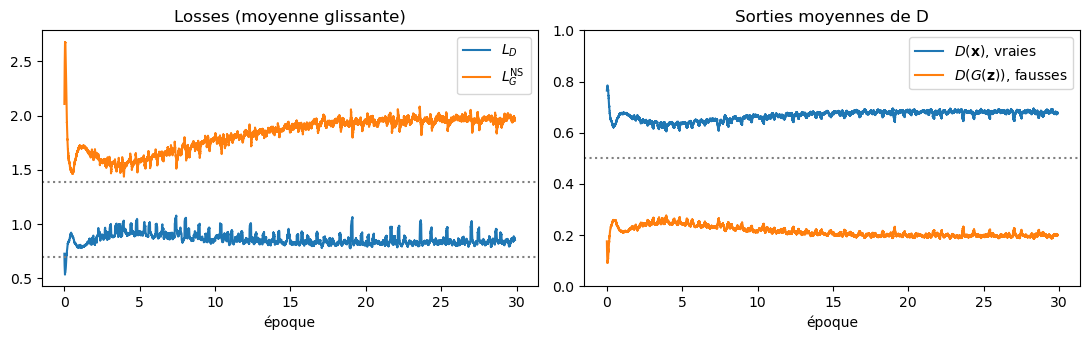

In [7]:
def smooth_curve(v, k=100):
    v = np.asarray(v)
    return np.convolve(v, np.ones(k) / k, mode="valid")

it_per_epoch = N // BATCH_SIZE
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for key, lab in [("loss_D", r"$L_D$"), ("loss_G", r"$L_G^{\mathrm{NS}}$")]:
    s = smooth_curve(history[key]); axes[0].plot(np.arange(len(s)) / it_per_epoch, s, label=lab)
axes[0].axhline(2 * math.log(2), ls=":", c="gray"); axes[0].axhline(math.log(2), ls=":", c="gray")
axes[0].set_xlabel("époque"); axes[0].set_title("Losses (moyenne glissante)"); axes[0].legend()
for key, lab in [("D_real", r"$D(\mathbf{x})$, vraies"), ("D_fake", r"$D(G(\mathbf{z}))$, fausses")]:
    s = smooth_curve(history[key]); axes[1].plot(np.arange(len(s)) / it_per_epoch, s, label=lab)
axes[1].axhline(0.5, ls=":", c="gray")
axes[1].set_ylim(0, 1); axes[1].set_xlabel("époque"); axes[1].set_title("Sorties moyennes de D"); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Évolution des images générées

Mêmes points latents `fixed_z` à différentes époques : les formes de chiffres apparaissent dès la première
époque, puis se précisent.

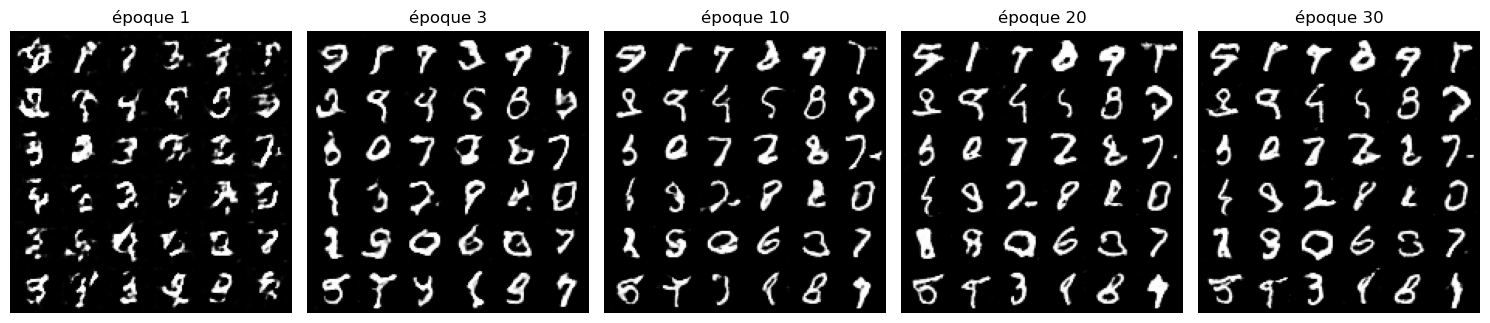

In [8]:
eps = sorted(snapshots)
fig, axes = plt.subplots(1, len(eps), figsize=(3 * len(eps), 3.2))
for ax, e in zip(np.atleast_1d(axes), eps):
    show_grid(snapshots[e][:36], nrow=6, title=f"époque {e}", ax=ax)
plt.tight_layout(); plt.show()

## 8. Génération de nouvelles images

On passe $G$ en mode **évaluation** (`G.eval()`) : la Batch Normalization utilise alors ses
statistiques moyennes estimées pendant l'entraînement, et non celles du batch courant.
On peut donc générer une seule image à la fois, et le résultat ne dépend pas des autres images du batch.

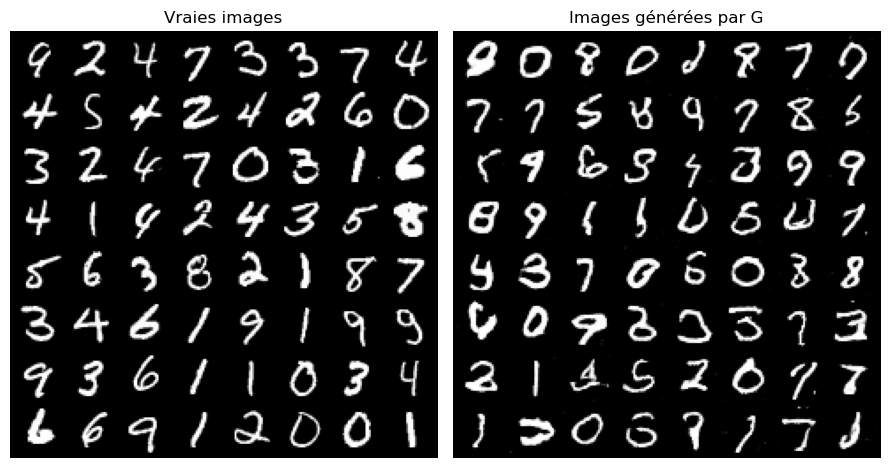

In [9]:
G.eval()
with torch.no_grad():
    samples = G(torch.randn(64, LATENT_DIM, device=device)).cpu()

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
show_grid(X[torch.randint(0, N, (64,), device=device)].cpu(), title="Vraies images", ax=axes[0])
show_grid(samples, title="Images générées par G", ax=axes[1])
plt.tight_layout(); plt.show()

## 9. Interpolation dans l'espace latent

On relie deux points latents $\mathbf{z}_1, \mathbf{z}_2$ et on génère $G\big((1-\alpha)\,\mathbf{z}_1 + \alpha\,\mathbf{z}_2\big)$
pour $\alpha \in [0, 1]$. Les transitions sont continues : $G$ a appris une variété lisse de chiffres,
et ne s'est pas contenté de mémoriser le dataset.

(Variante : l'interpolation **sphérique** *slerp* reste mieux dans la zone de forte densité de $\mathcal{N}(\mathbf{0}, \mathbf{I})$,
car en grande dimension les $\mathbf{z}$ se concentrent près de la sphère de rayon $\sqrt{l} = 10$, et le milieu
d'un segment est plus proche de l'origine.)

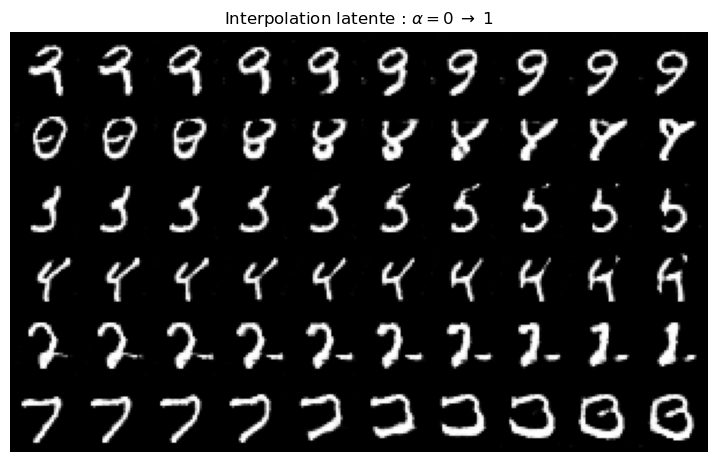

In [10]:
def slerp(z1, z2, alpha):
    # Interpolation sphérique entre z1 et z2 (même forme)
    omega = torch.arccos(torch.clamp(F.cosine_similarity(z1, z2, dim=-1), -1, 1)).unsqueeze(-1)
    so = torch.sin(omega)
    return torch.sin((1 - alpha) * omega) / so * z1 + torch.sin(alpha * omega) / so * z2

N_ROWS, N_STEPS = 6, 10
alphas = torch.linspace(0, 1, N_STEPS, device=device)
torch.manual_seed(3)
z1, z2 = torch.randn(N_ROWS, LATENT_DIM, device=device), torch.randn(N_ROWS, LATENT_DIM, device=device)
z_path = torch.stack([slerp(z1, z2, a) for a in alphas], dim=1).reshape(-1, LATENT_DIM)  # ligne par ligne

with torch.no_grad():
    interp = G(z_path).cpu()

plt.figure(figsize=(9, 5.6))
show_grid(interp, nrow=N_STEPS, title=r"Interpolation latente : $\alpha = 0 \;\to\; 1$")
plt.show()

## 10. Figures pour les slides

On sauvegarde en PDF (vectoriel autour des images, texte en LaTeX si disponible) dans `figures/` :

* `gan_mnist_samples.pdf` : grille d'images générées (remplace `generated_data.pdf` du slide « Exemple ») ;
* `gan_mnist_progress.pdf` : évolution au cours des époques ;
* `gan_mnist_losses.pdf` : courbes d'entraînement ;
* `gan_mnist_interp.pdf` : interpolation latente.

In [11]:
import shutil
USETEX = shutil.which("latex") is not None
mpl.rcParams.update({
    "text.usetex": USETEX,
    "text.latex.preamble": r"\usepackage[T1]{fontenc}\usepackage{amsmath,amssymb,bm}"
                           r"\renewcommand{\familydefault}{\sfdefault}",
    "font.size": 9, "axes.linewidth": 0.6,
})
INK, MUTED, BLUE, ORANGE = "#1f1f1e", "#8a8984", "#2a78d6", "#eb6834"

def grid_np(imgs, nrow):
    g = make_grid(imgs, nrow=nrow, padding=2, pad_value=1.0, normalize=True, value_range=(-1, 1))
    return g[0].numpy()

# (a) grille d'échantillons
fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.imshow(grid_np(samples[:64], 8), cmap="gray", interpolation="nearest"); ax.axis("off")
fig.savefig(os.path.join(FIG_DIR, "gan_mnist_samples.pdf"), bbox_inches="tight", pad_inches=0.02)
plt.close(fig)

# (b) progression
fig, axes = plt.subplots(1, len(eps), figsize=(1.45 * len(eps), 1.7))
for ax, e in zip(np.atleast_1d(axes), eps):
    ax.imshow(grid_np(snapshots[e][:16], 4), cmap="gray", interpolation="nearest"); ax.axis("off")
    ax.set_title(f"\\'epoque {e}" if USETEX else f"époque {e}", fontsize=8, color=INK)
fig.tight_layout(pad=0.3)
fig.savefig(os.path.join(FIG_DIR, "gan_mnist_progress.pdf"), bbox_inches="tight", pad_inches=0.02)
plt.close(fig)

# (c) courbes
fig, axes = plt.subplots(1, 2, figsize=(5.6, 1.9))
ep = lambda s: np.arange(len(s)) / it_per_epoch
s = smooth_curve(history["loss_D"]); axes[0].plot(ep(s), s, color=BLUE, lw=1.2, label=r"$L_D$")
s = smooth_curve(history["loss_G"]); axes[0].plot(ep(s), s, color=ORANGE, lw=1.2, label=r"$L_G^{\mathrm{NS}}$")
axes[0].legend(frameon=False, fontsize=8); axes[0].set_xlabel(r"\'epoque" if USETEX else "époque")
s = smooth_curve(history["D_real"]); axes[1].plot(ep(s), s, color=BLUE, lw=1.2, label=r"$D(\mathbf{x})$")
s = smooth_curve(history["D_fake"]); axes[1].plot(ep(s), s, color=ORANGE, lw=1.2, label=r"$D(G(\mathbf{z}))$")
axes[1].axhline(0.5, color=MUTED, lw=0.7, ls=":"); axes[1].set_ylim(0, 1)
axes[1].legend(frameon=False, fontsize=8); axes[1].set_xlabel(r"\'epoque" if USETEX else "époque")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(pad=0.3)
fig.savefig(os.path.join(FIG_DIR, "gan_mnist_losses.pdf"), bbox_inches="tight", pad_inches=0.02)
plt.close(fig)

# (d) interpolation
fig, ax = plt.subplots(figsize=(4.6, 2.9))
ax.imshow(grid_np(interp, N_STEPS), cmap="gray", interpolation="nearest"); ax.axis("off")
fig.savefig(os.path.join(FIG_DIR, "gan_mnist_interp.pdf"), bbox_inches="tight", pad_inches=0.02)
plt.close(fig)

mpl.rcParams.update(mpl.rcParamsDefault)
print("Figures sauvegardées dans", os.path.abspath(FIG_DIR), "| usetex =", USETEX)

Figures sauvegardées dans /Users/jeremiecabessa/Desktop/ROOT/Courses/NEURAL_NETWORKS/15_GenerativeAdversarialNetworks/figures | usetex = True


## 11. Pour aller plus loin (exercices)

* Remplacer $L_G^{\mathrm{NS}}$ par la loss saturante $\frac1m\sum_j \log(1 - D(G(\mathbf{z}_j)))$ : que deviennent $D(G(\mathbf{z}))$ et les images au début ?
* Mettre `BETAS = (0.9, 0.999)` (Adam par défaut) ou `LR = 1e-3` : le jeu reste-t-il équilibré ?
* Retirer la Batch Normalization de $G$ : observe-t-on du *mode collapse* (toujours les mêmes chiffres) ?
* Mettre `REAL_LABEL = 1.0` (pas de label smoothing).
* Conditionner $G$ et $D$ sur le chiffre voulu (**conditional GAN**) en concaténant un *one-hot* de la classe.